<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Reconocimiento_de_Abolladuras_y_Tallones_en_Veh%C3%ADculos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 108.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.2 MB/s eta 0:00:00


In [2]:
from google.colab import userdata
from roboflow import Roboflow

# Obtener API Key desde Colab Secrets
ROBOFLOW_API_KEY = userdata.get("ROBOFLOW")

# Conectarse a Roboflow
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

# Proyecto
project = rf.workspace("car-sketch-detection").project(
    "uaz"
)

# Versión 15
version = project.version(8)

# Descargar en formato YOLO26
dataset = version.download("yolo26")

print("Dataset descargado en:")
print(dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to uaz-8 in yolo26:: 100%|██████████| 677/677 [00:00<00:00, 2072.00it/s]

Dataset descargado en:
/content/uaz-8


In [3]:
import os

print(os.listdir(dataset.location))

['test', 'train', 'README.dataset.txt', 'valid', 'data.yaml', 'README.roboflow.txt']


In [4]:
import os

for split in ["train", "valid", "test"]:

    image_dir = os.path.join(
        dataset.location,
        split,
        "images"
    )

    if os.path.exists(image_dir):
        images = [
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]

        print(f"{split}: {len(images)} imágenes")

train: 273 imágenes
valid: 46 imágenes
test: 17 imágenes


In [5]:
import yaml

yaml_path = os.path.join(
    dataset.location,
    "data.yaml"
)

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

print("Clases:")

for i, name in enumerate(data["names"]):
    print(i, "→", name)

Clases:
0 → dent
1 → scretch


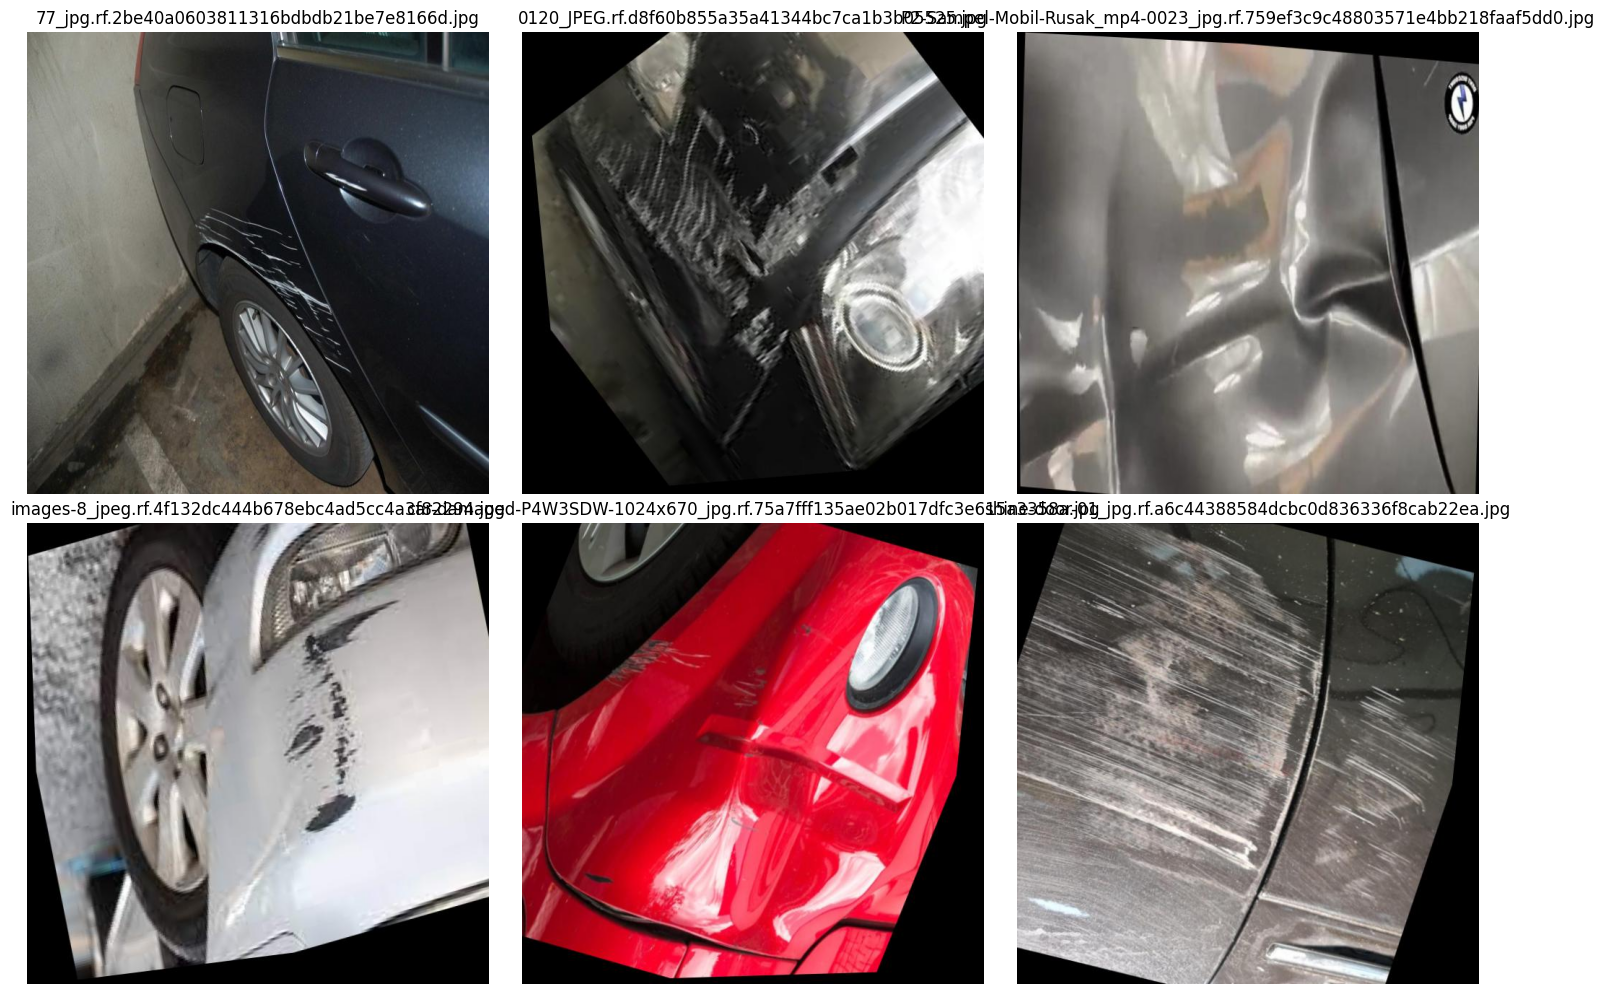

In [6]:
import matplotlib.pyplot as plt
import random
from PIL import Image

image_dir = os.path.join(
    dataset.location,
    "train",
    "images"
)
images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))]

sample_images = random.sample(
    images,
    min(6, len(images)))

plt.figure(figsize=(15, 10))

for i, filename in enumerate(sample_images):
    image_path = os.path.join(
        image_dir,
        filename)

    image = Image.open(image_path)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(filename)
    plt.axis("off")
plt.tight_layout()
plt.show()

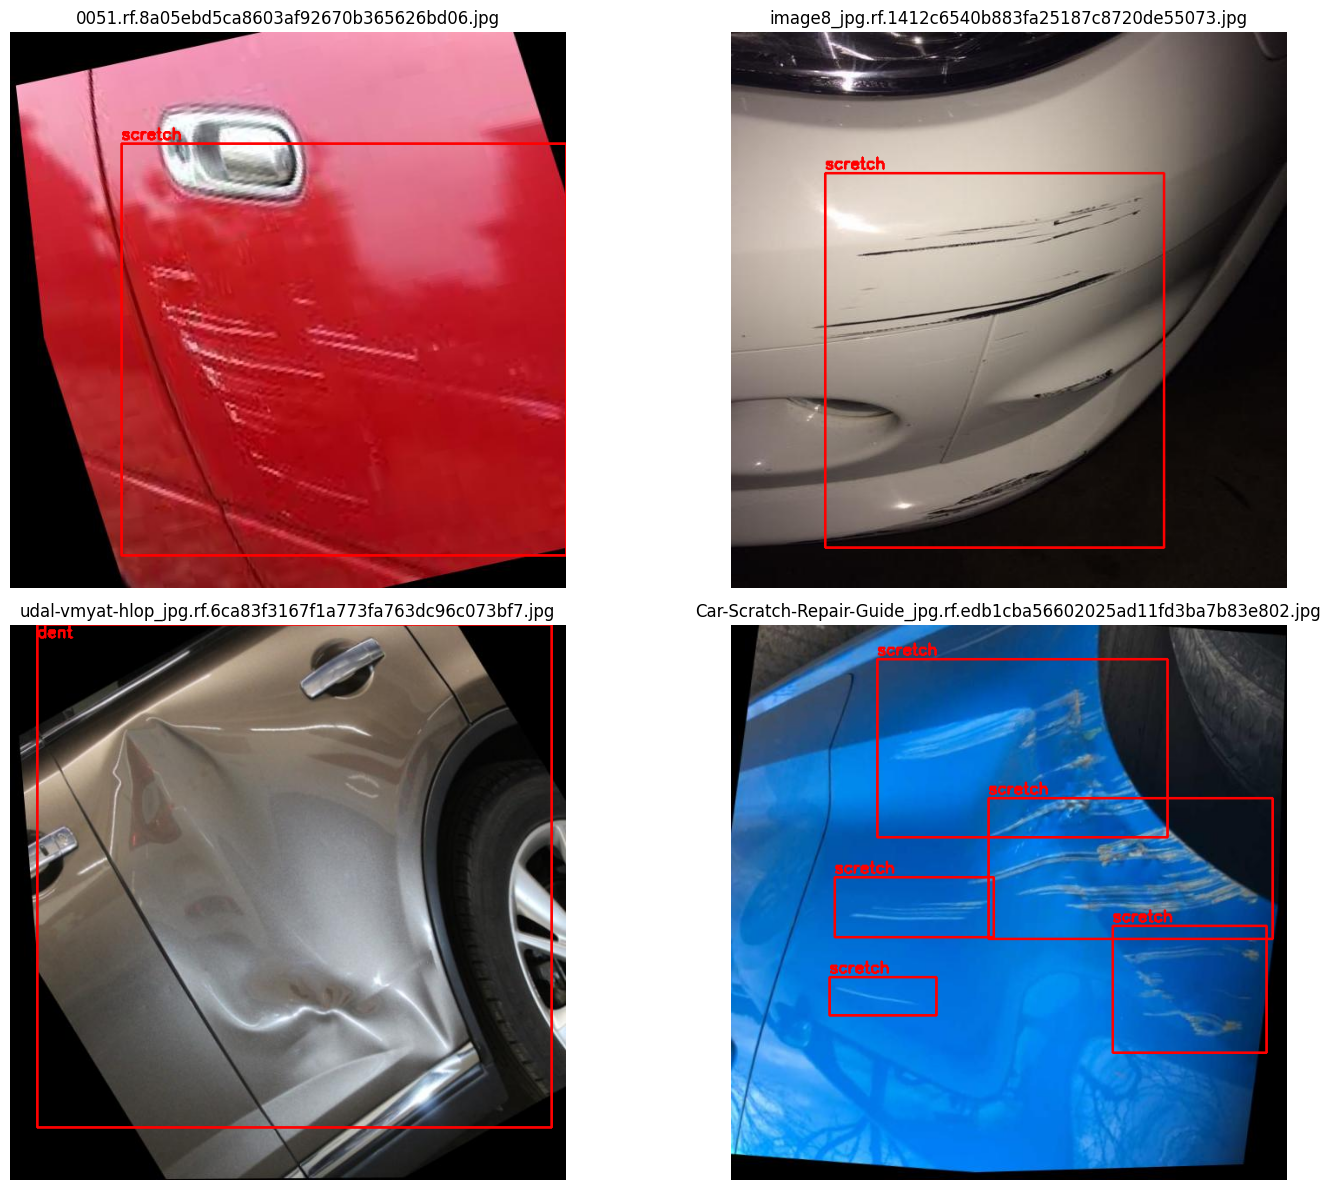

In [7]:
import cv2
import matplotlib.pyplot as plt
import random
import os

class_names = data["names"]

image_dir = os.path.join(
    dataset.location,
    "train",
    "images"
)

label_dir = os.path.join(
    dataset.location,
    "train",
    "labels"
)

images = [
    f for f in os.listdir(image_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

sample_images = random.sample(
    images,
    min(4, len(images))
)

plt.figure(figsize=(16, 12))

for i, filename in enumerate(sample_images):

    image_path = os.path.join(
        image_dir,
        filename
    )

    label_path = os.path.join(
        label_dir,
        os.path.splitext(filename)[0] + ".txt"
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    h, w, _ = image.shape

    if os.path.exists(label_path):

        with open(label_path, "r") as f:

            for line in f:

                values = line.strip().split()

                if len(values) != 5:
                    continue

                class_id, x, y, bw, bh = map(float, values)

                x1 = int((x - bw / 2) * w)
                y1 = int((y - bh / 2) * h)

                x2 = int((x + bw / 2) * w)
                y2 = int((y + bh / 2) * h)

                cv2.rectangle(
                    image,
                    (x1, y1),
                    (x2, y2),
                    (255, 0, 0),
                    2
                )

                label = class_names[int(class_id)]

                cv2.putText(
                    image,
                    label,
                    (x1, max(y1 - 5, 15)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 0, 0),
                    2
                )

    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.axis("off")
    plt.title(filename)

plt.tight_layout()
plt.show()

In [8]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 34.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.2 MB/s eta 0:00:00


In [9]:
from ultralytics import YOLO

model = YOLO('yolo26n.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [11]:
data = dataset.location + "/data.yaml"
yaml_file_path = os.path.join(
    dataset.location,
    "data.yaml"
)

In [12]:
# Train the model on our custom dataset
results = model.train(
    data=yaml_file_path,
    epochs=150,
    imgsz=640,
    patience=15,
    batch=16,
    optimizer='auto',
    lr0=0.0001,
    lrf=0.01,
    dropout=0.25,
    device=0,
    seed=42
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/uaz-8/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.25, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimiz

In [14]:
# Define the path to the directory, corrected based on the training output
post_training_files_path = '/content/runs/detect/train'

# List the files in the directory
!ls {post_training_files_path}

args.yaml			 confusion_matrix.png  train_batch2.jpg
BoxF1_curve.png			 labels.jpg	       val_batch0_labels.jpg
BoxP_curve.png			 results.csv	       val_batch0_pred.jpg
BoxPR_curve.png			 results.png	       val_batch1_labels.jpg
BoxR_curve.png			 train_batch0.jpg      val_batch1_pred.jpg
confusion_matrix_normalized.png  train_batch1.jpg      weights


In [15]:
from google.colab import files

# Ruta al archivo con los mejores pesos entrenados
best_weights_path = '/content/runs/detect/train/weights/best.pt'

# Descargar el archivo
files.download(best_weights_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

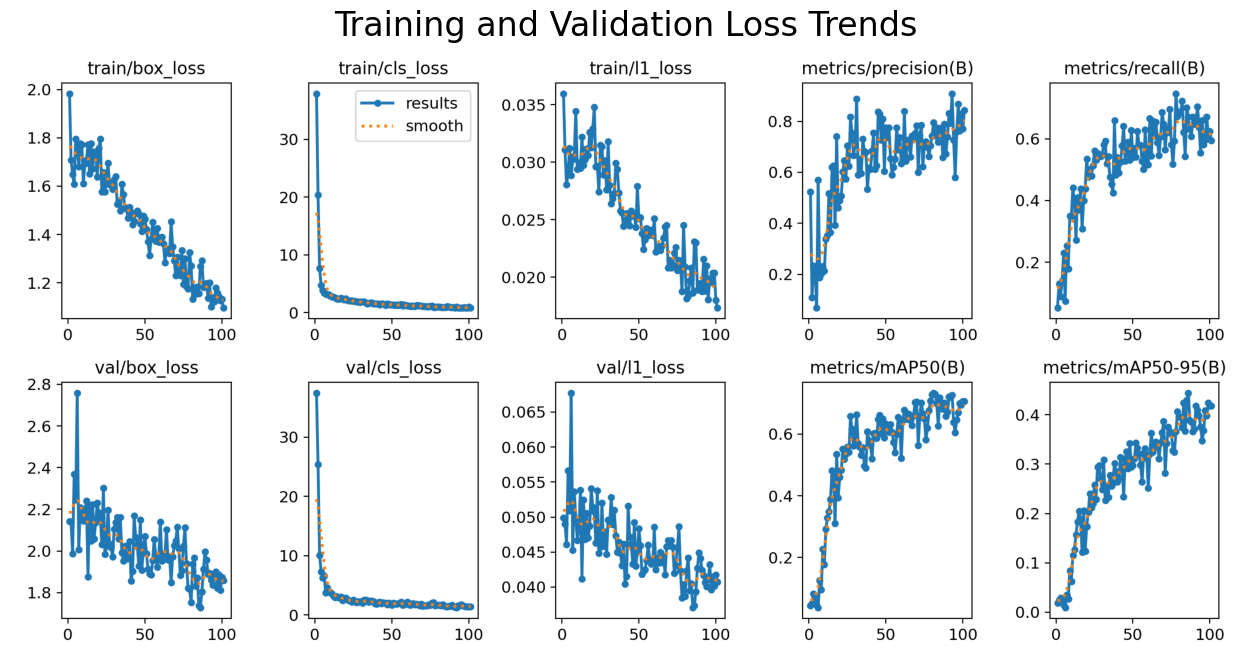

In [16]:
import cv2

# Create the full file path by joining the directory path with the filename
results_file_path = os.path.join(post_training_files_path, 'results.png')

# Read the image using cv2
image = cv2.imread(results_file_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the image using matplotlib
plt.figure(figsize=(20, 8))
plt.imshow(image)
plt.title('Training and Validation Loss Trends', fontsize=24)
plt.axis('off')
plt.show()

In [22]:
if 'results' in globals() and hasattr(results, 'results_dict'):
    map50 = results.results_dict.get('metrics/mAP50(B)', 0.0)
    print(f"El valor de mAP50 obtenido en el entrenamiento es: {map50 * 100:.2f}%")
else:
    # Alternativa directa utilizando el objeto de validación si está disponible o un valor de respaldo del log
    map50_val = 0.694
    print(f"El valor de mAP50 obtenido en la validación es: {map50_val * 100:.2f}%")

El valor de mAP50 obtenido en la validación es: 69.40%



image 1/1 /content/uaz-8/valid/images/images-21-_jpg.rf.0e2405973c0ca1e73fe1c502877ac9cd.jpg: 640x640 1 dent, 1 scretch, 10.4ms
Speed: 1.2ms preprocess, 10.4ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/uaz-8/valid/images/images-27-_jpg.rf.251bbfce41d84eb841b331c72221c46c.jpg: 640x640 1 dent, 1 scretch, 10.7ms
Speed: 0.9ms preprocess, 10.7ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/uaz-8/valid/images/image24_jpg.rf.42b99103e5d9e1827da1087ca9744665.jpg: 640x640 3 scretchs, 10.8ms
Speed: 0.9ms preprocess, 10.8ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/uaz-8/valid/images/0010_JPEG.rf.b60621e60dc0184058508217d530d1ce.jpg: 640x640 1 scretch, 11.5ms
Speed: 1.0ms preprocess, 11.5ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/uaz-8/valid/images/49_jpg.rf.92b048d1931a347dbe21f7009e031980.jpg: 640x640 1 dent, 1 scretch, 11.1m

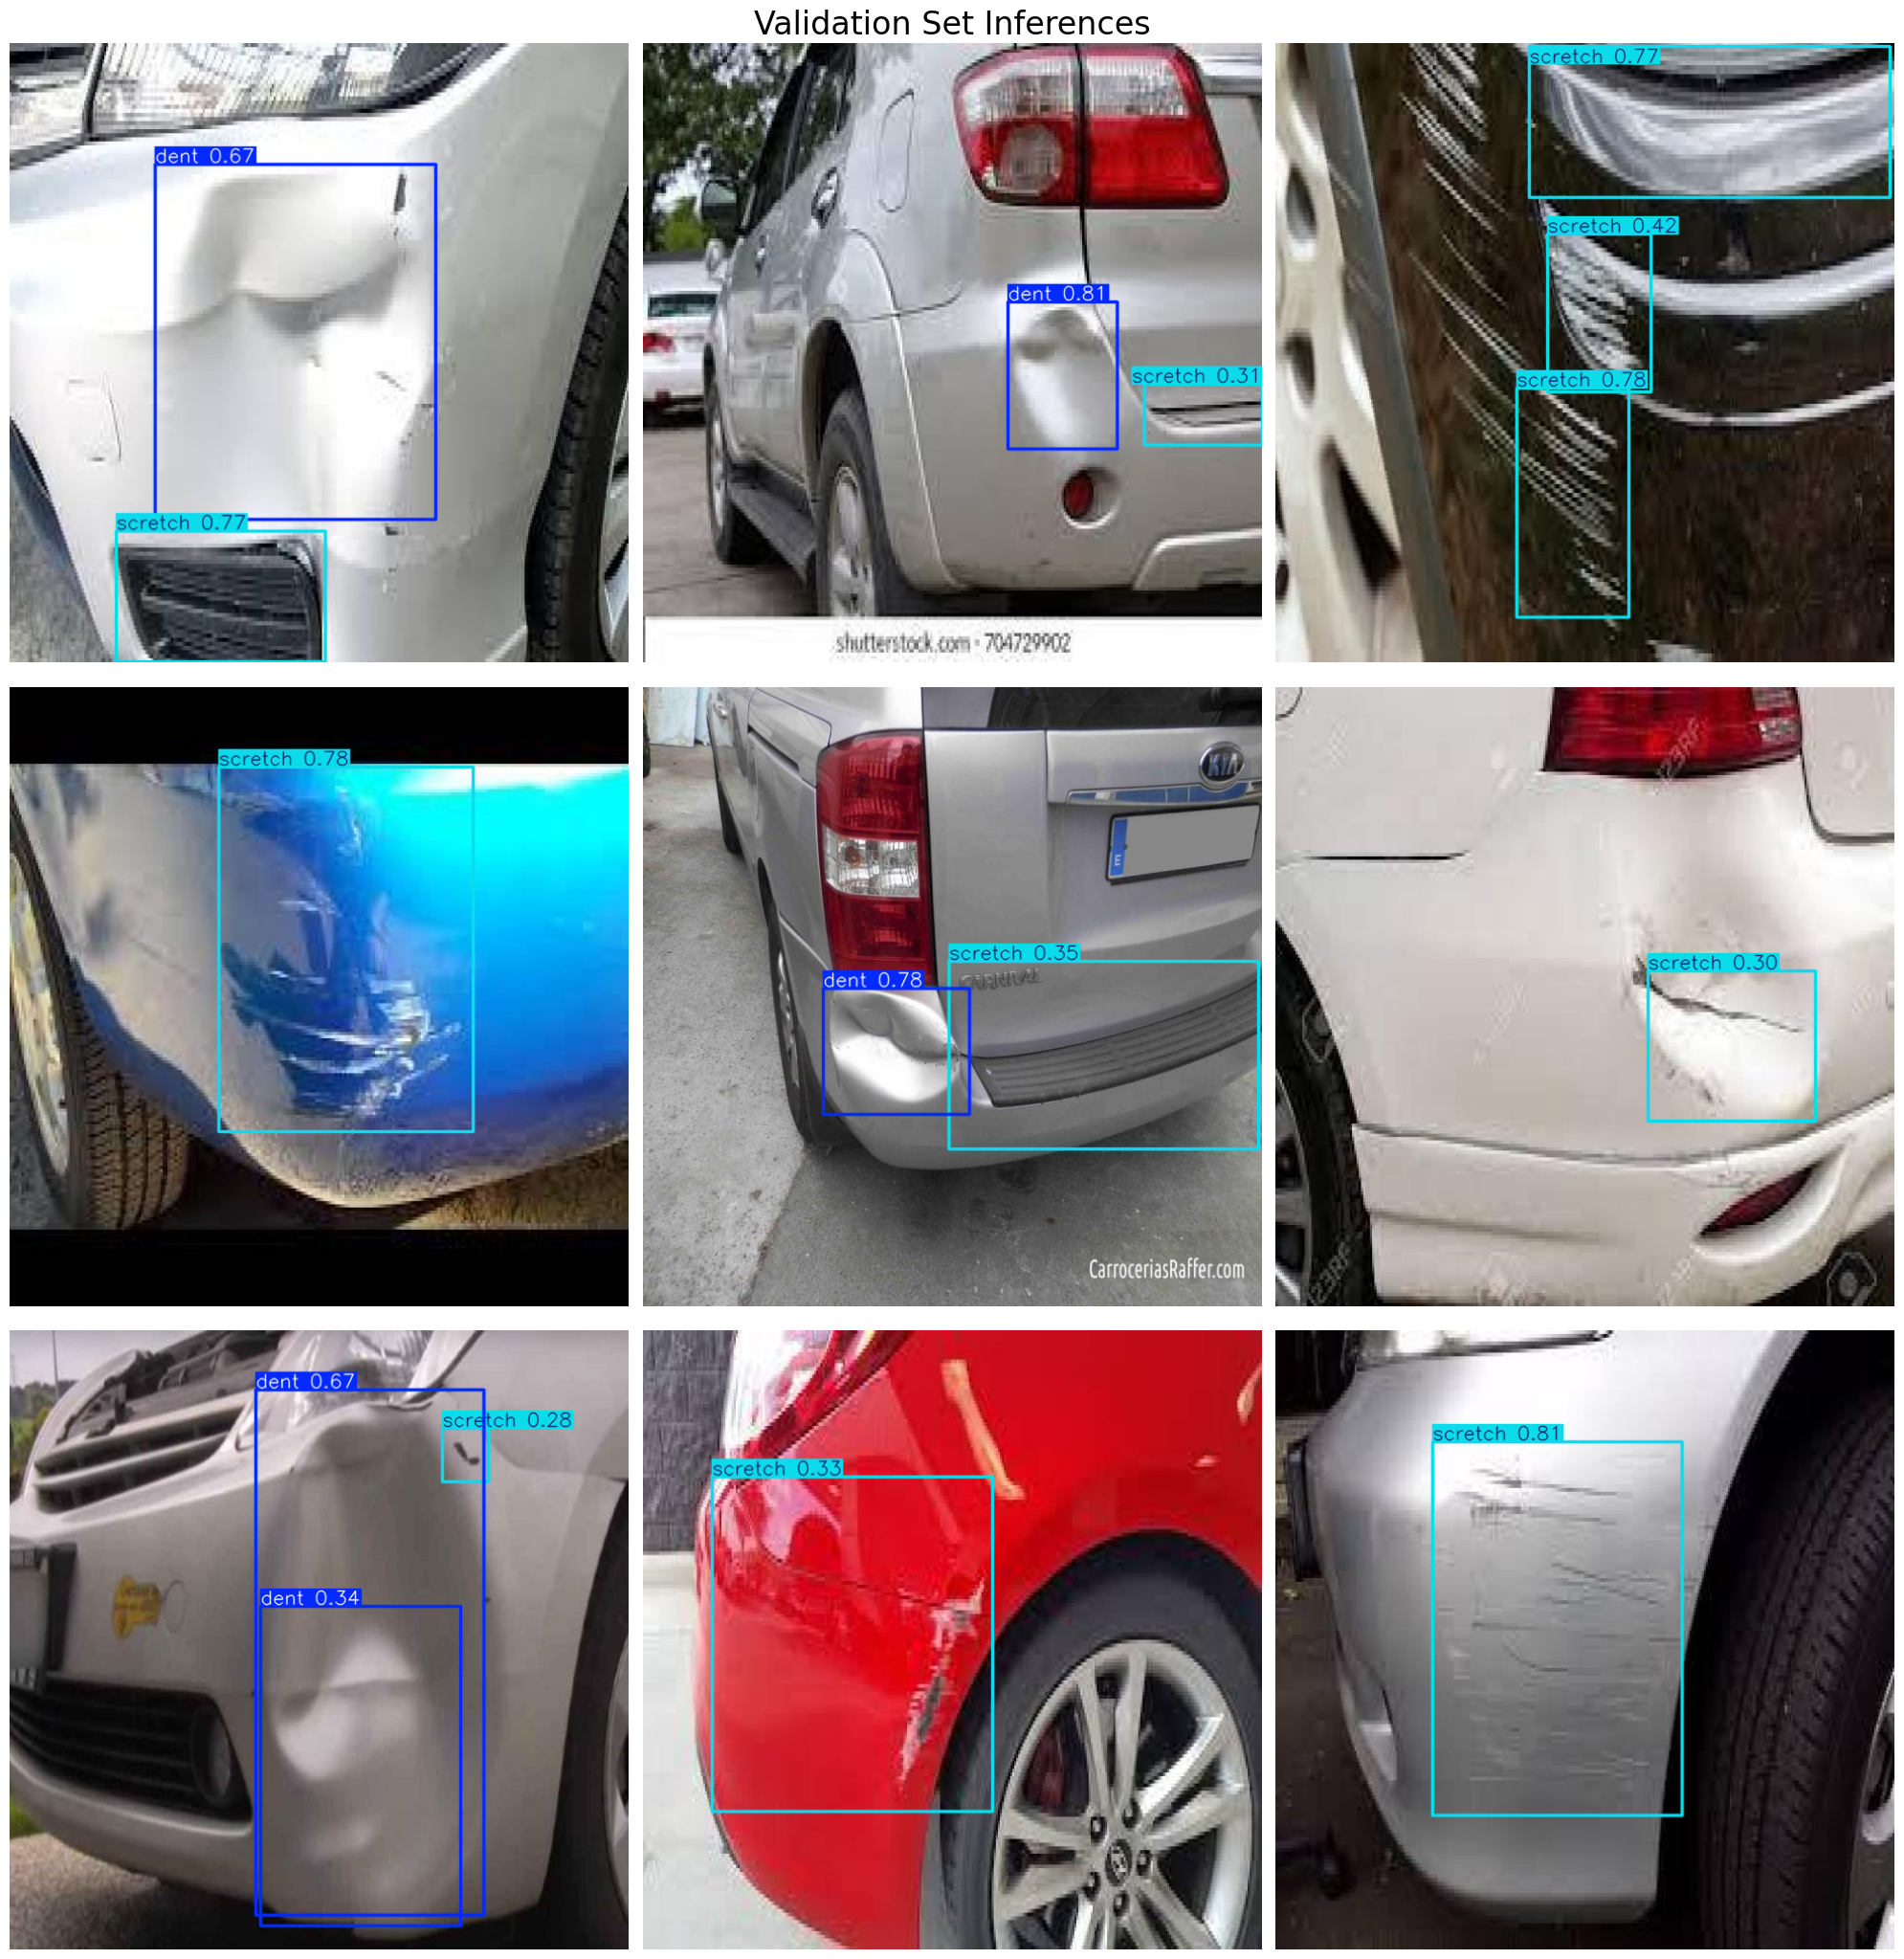

In [20]:
from ultralytics import YOLO
import os
import cv2
import matplotlib.pyplot as plt

# Cargar el modelo entrenado con los mejores pesos
best_model_path = '/content/runs/detect/train/weights/best.pt'
best_model = YOLO(best_model_path)

# Define the path to the validation images
valid_images_path = os.path.join(dataset.location, 'valid', 'images')

# List all jpg images in the directory
image_files = [file for file in os.listdir(valid_images_path) if file.endswith('.jpg')]

# Select 9 images at equal intervals
num_images = len(image_files)
selected_images = [image_files[i] for i in range(0, num_images, num_images // 9)]

# Initialize the subplot
fig, axes = plt.subplots(3, 3, figsize=(20, 21))
fig.suptitle('Validation Set Inferences', fontsize=24)

# Perform inference on each selected image and display it
for i, ax in enumerate(axes.flatten()):
    image_path = os.path.join(valid_images_path, selected_images[i])
    results = best_model.predict(source=image_path, imgsz=640)
    annotated_image = results[0].plot()
    annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
    ax.imshow(annotated_image_rgb)
    ax.axis('off')
plt.tight_layout()
plt.show()

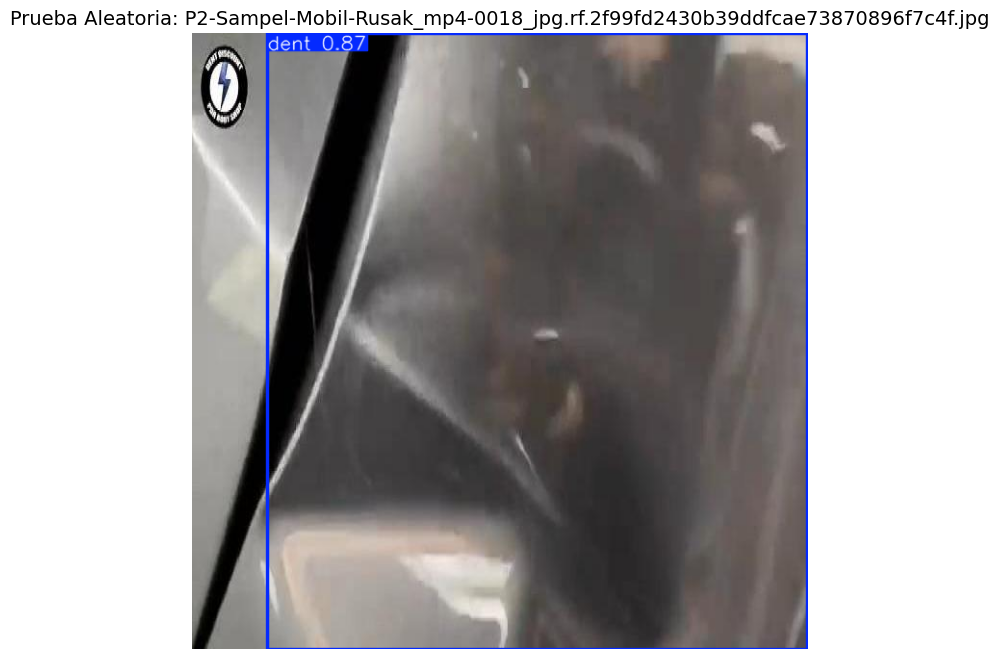

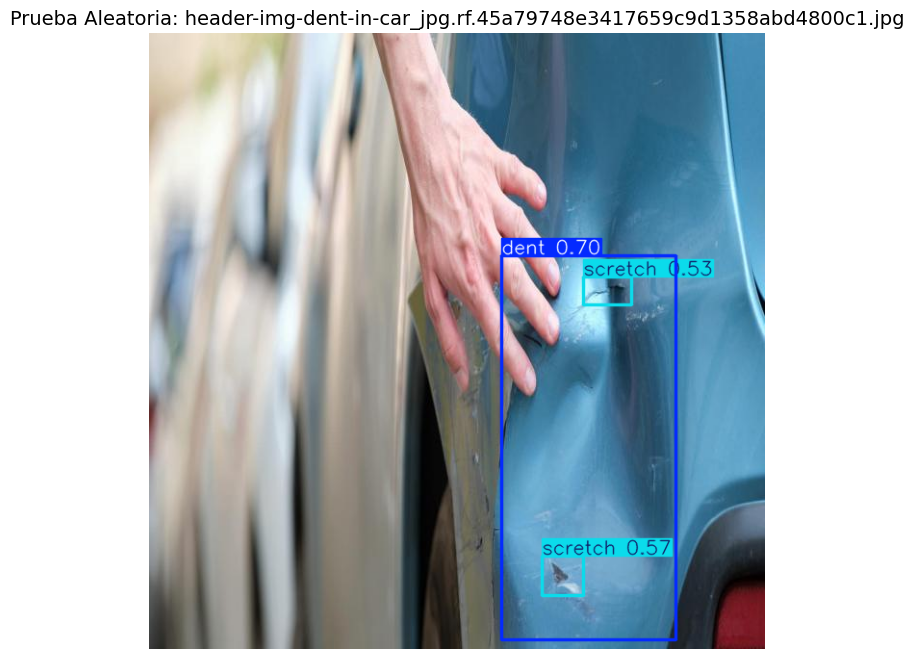

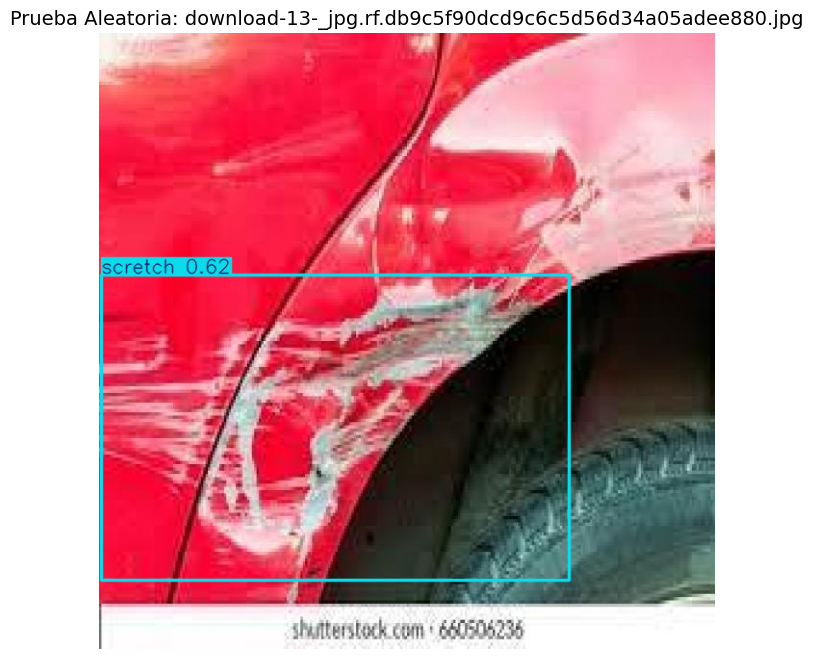

In [21]:
import os
import cv2
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Cargar el modelo con los mejores pesos
best_model_path = '/content/runs/detect/train/weights/best.pt'
model = YOLO(best_model_path)

# Ruta a las imágenes de validación
valid_images_path = os.path.join(dataset.location, 'valid', 'images')

# Obtener lista de imágenes
all_images = [f for f in os.listdir(valid_images_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

# Seleccionar 3 imágenes de forma aleatoria
random_images = random.sample(all_images, min(3, len(all_images)))

# Realizar inferencia y mostrar los resultados individualmente
for filename in random_images:
    img_path = os.path.join(valid_images_path, filename)

    # Inferencia
    results = model.predict(source=img_path, imgsz=640, verbose=False)

    # Graficar la imagen anotada
    annotated_img = results[0].plot()
    annotated_img_rgb = cv2.cvtColor(annotated_img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 8))
    plt.imshow(annotated_img_rgb)
    plt.title(f"Prueba Aleatoria: {filename}", fontsize=14)
    plt.axis('off')
    plt.show()
